# 01-6. 이론 검증 Ⅰ: 결빙 조건

01(데이터 탐색)의 13장 앞부분(13-1 ~ 13-4). 01-1(0장)에서 세운 가설 가운데 결빙이 생기는 조건에 관한 것(H1~H5)을 이 자료로 확인한다.

01 구성: 01-1 이론(0장) · 01-2 자료 구성·품질(1~3장) · 01-3 노면온도·노면상태(4~5장) · 01-4 결빙 기상 조건·검증 지점(6~10장) · 01-5 도로·지형·목표안개(11~12장) · **01-6 이론 검증 Ⅰ(13-1~13-4)** · 01-7 이론 검증 Ⅱ·정리(13-5~14장)

- 입력: 01-4의 RWIS + 최근접 AWS·ASOS 결합 자료(`m`), 01-2의 지점 정보 (`data/interim/`)

**목차**

- 13-1. 노면센서의 판정 구조와 결빙 온도 (H1, H2)
- 13-2. 결빙 경로 분류 (H1, H4)
- 13-3. 서리 조건 (H3)
- 13-4. 냉각 속도, 동결-융해, 일출·일몰 (H4, H5)

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]  # notebooks/<단계 폴더>/ 에서 실행
sys.path.insert(0, str(ROOT))

from src import config

In [2]:
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
from cycler import cycler
from matplotlib import font_manager

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# 한글 글꼴 (설치된 것 중 먼저 찾은 것)
for font in ["NanumGothic", "Malgun Gothic", "AppleGothic"]:
    if any(f.name == font for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font
        break
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({
    "axes.unicode_minus": False,
    "axes.prop_cycle": cycler(color=PALETTE),
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 100, "lines.linewidth": 1.5,
})
ROUTE_COLORS = {"서해안": PALETTE[0], "호남선": PALETTE[1], "통영-대전중부선": PALETTE[2]}
INK, MUTED = "#0b0b0b", "#898781"
HOLDOUT = list(config.HOLDOUT_STATIONS)
CRS = 5179

In [3]:
m = pd.read_parquet(config.INTERIM_DIR / "rwis_weather.parquet")  # 01-4(6-1)의 RWIS + 최근접 AWS·ASOS 결합 자료
st_info = pd.read_parquet(config.INTERIM_DIR / "stations_rwis.parquet").set_index("stn")
STATE_NAMES = {1: "Dry", 2: "Wet", 3: "Snow", 4: "Ice", 10: "저시정", 11: "물고임",
               12: "Damp+저온(제빙)", 13: "결빙시작(제빙)", 14: "Damp", 15: "판별불가",
               0: "미정의(0)", -999: "결측"}  # 노면상태 코드 (01-3의 5-1)
print(m.shape)

(587445, 56)


## 13. 이론 검증 분석

0장의 가설(H1~H11)을 이 자료로 확인한다. 주로 6장의 결합 자료 `m`(RWIS + 최근접 AWS·ASOS)을 쓰고,
기온·습도를 직접 재는 기본·거점 관측소 9곳은 자체 센서 값을 쓴다.

### 13-1. 노면센서의 판정 구조와 결빙 온도 (H1, H2)

노면상태 코드 12·13의 정의에는 "노면온도 1.5°C 미만"이 들어 있다. 센서가 이 온도를 기준으로 결빙 계열 상태를 판정한다면
Ice·Snow 등은 1.5°C 이상에서 거의 나오지 않아야 한다.

In [4]:
v = m[m["state"].notna() & m["rst"].notna()].copy()
gate = v.groupby("state")["rst"].agg(["size", lambda s: s.quantile(0.95), lambda s: s.quantile(0.99), "max",
                                      lambda s: (s >= 1.5).mean()])
gate.columns = ["관측수", "95% 분위", "99% 분위", "최댓값", "1.5°C 이상 비율"]
gate.rename(index=STATE_NAMES).round(3)

,관측수,95% 분위,99% 분위,최댓값,1.5°C 이상 비율
state,,,,,
Dry,424621,17.800,22.900,33.1,0.678
Wet,68499,12.100,14.900,22.0,0.545
Snow,2245,0.700,1.400,7.5,0.010
Ice,303,1.200,1.500,3.0,0.017
저시정,242,6.995,12.718,13.0,0.533
Damp+저온(제빙),15002,1.300,1.500,2.1,0.020
결빙시작(제빙),290,1.200,1.400,1.5,0.007
Damp,68022,12.700,16.900,30.1,0.590
판별불가,4106,1.100,1.900,3.7,0.021


Snow·Ice·Damp+저온(12)·결빙시작(13)·판별불가(15)는 98% 이상이 노면 1.5°C 미만에서 나오고, Dry·Wet·Damp는 절반 이상이 1.5°C 이상이다.
**센서가 노면 1.5°C를 경계로 결빙 계열 상태를 판정한다**는 뜻이며 코드 정의와 맞다. 추정 노면온도가 1.5°C를 넘으면 Ice가 나올 가능성은 거의 없다.

이제 Bonanno et al.(2010)의 기준(강수가 있으면 노면 < 1°C, 없으면 < 0°C에서 결빙)을 강수 상태별 Ice 비율로 확인한다.
강수 상태는 최근접 AWS의 강수 감지로 나눈다.

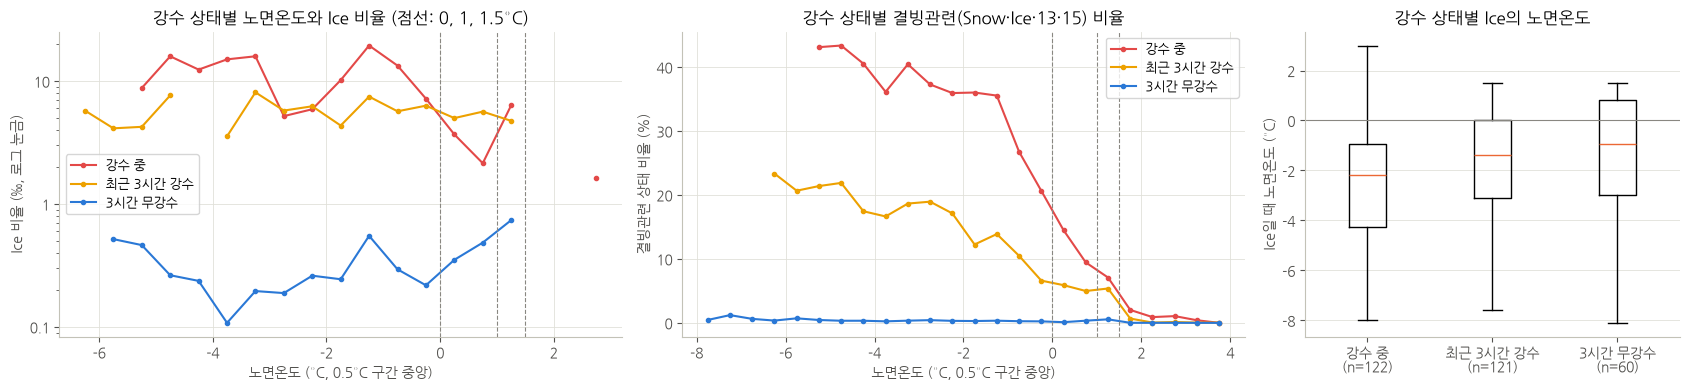

,Ice 건수,Ice 노면온도 중앙값,Ice 중 노면 ≤ 0°C,Ice 중 노면 < 1°C,노면 < 1.5°C 관측수,노면 < 1.5°C일 때 Ice(‰)
강수상태,,,,,,
강수 중,122,-2.20,0.885,0.926,11159,10.664
최근 3시간 강수,121,-1.40,0.752,0.901,21555,5.567
3시간 무강수,60,-0.95,0.617,0.767,184826,0.319


In [5]:
PRECIP_GROUPS = ["강수 중", "최근 3시간 강수", "3시간 무강수"]
PRECIP_COLORS = [PALETTE[7], PALETTE[3], PALETTE[0]]
v["강수상태"] = np.select([v["aws_rain"] >= 1, v["강수시간3h"] > 0], PRECIP_GROUPS[:2], PRECIP_GROUPS[2])
v["노면온도 구간"] = pd.cut(v["rst"], np.arange(-8, 4.01, 0.5))
p_ice = v.groupby(["강수상태", "노면온도 구간"], observed=True)["state"].agg(
    관측수="size", Ice=lambda s: (s == 4).mean() * 1000, 결빙관련=lambda s: s.isin([3, 4, 13, 15]).mean() * 100)
ice_v = v[v["state"] == 4]
fig, axes = plt.subplots(1, 3, figsize=(17, 4), gridspec_kw={"width_ratios": [1.2, 1.2, 0.8]})
for grp, color in zip(PRECIP_GROUPS, PRECIP_COLORS):
    d = p_ice.loc[grp]
    d = d[d["관측수"] >= 300]
    x = [c.mid for c in d.index]
    axes[0].plot(x, d["Ice"].where(d["Ice"] > 0), marker="o", markersize=3, color=color, label=grp)
    axes[1].plot(x, d["결빙관련"], marker="o", markersize=3, color=color, label=grp)
axes[0].set_yscale("log")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, _: f"{y:g}"))
axes[0].set_ylabel("Ice 비율 (‰, 로그 눈금)")
axes[1].set_ylabel("결빙관련 상태 비율 (%)")
for ax in axes[:2]:
    for t in (0, 1, 1.5):
        ax.axvline(t, color=MUTED, linewidth=0.8, linestyle="--")
    ax.set_xlabel("노면온도 (°C, 0.5°C 구간 중앙)")
    ax.legend(fontsize=9)
axes[0].set_title("강수 상태별 노면온도와 Ice 비율 (점선: 0, 1, 1.5°C)")
axes[1].set_title("강수 상태별 결빙관련(Snow·Ice·13·15) 비율")
axes[2].boxplot([ice_v.loc[ice_v["강수상태"] == g, "rst"] for g in PRECIP_GROUPS],
                tick_labels=[f"{g}\n(n={(ice_v['강수상태'] == g).sum()})" for g in PRECIP_GROUPS],
                showfliers=False, medianprops={"color": PALETTE[1]})
axes[2].axhline(0, color=MUTED, linewidth=0.8)
axes[2].set_ylabel("Ice일 때 노면온도 (°C)")
axes[2].set_title("강수 상태별 Ice의 노면온도")
axes[2].grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
below = v[v["rst"] < 1.5]
pd.DataFrame({
    "Ice 건수": ice_v.groupby("강수상태").size(),
    "Ice 노면온도 중앙값": ice_v.groupby("강수상태")["rst"].median(),
    "Ice 중 노면 ≤ 0°C": ice_v.groupby("강수상태")["rst"].apply(lambda s: (s <= 0).mean()),
    "Ice 중 노면 < 1°C": ice_v.groupby("강수상태")["rst"].apply(lambda s: (s < 1).mean()),
    "노면 < 1.5°C 관측수": below.groupby("강수상태").size(),
    "노면 < 1.5°C일 때 Ice(‰)": below.groupby("강수상태")["state"].apply(lambda s: (s == 4).mean() * 1000),
}).reindex(PRECIP_GROUPS).round(3)

- 노면 1.5°C 미만에서 Ice 비율은 강수 중 10.7‰, 최근 3시간 강수 5.6‰, 3시간 무강수 0.3‰이다.
  **같은 노면온도에서도 강수가 있느냐에 따라 Ice 비율이 30배 넘게 다르다** (H1 지지).
- 강수 중에는 노면이 1.5°C 아래로 내려가면서 결빙관련 상태가 2%에서 40% 넘게까지 차츰 늘어난다. 0°C나 1°C에서 갑자기 바뀌는 문턱은 보이지 않는다.
- Bonanno 기준과 비교하면, 강수 중 Ice의 93%는 노면 < 1°C였다 (기준과 맞음). 강수가 없을 때 Ice는 62%만 노면 ≤ 0°C이고
  나머지는 0~1.5°C였다. **"강수가 없으면 0°C 미만"이라는 기준은 이 센서의 판정과 일부만 맞는다** (H2 부분 지지).
- 강수 없이 노면이 1.5°C 미만인 관측은 18만 건이 넘지만 Ice는 0.3‰뿐이다. 온도 기준만 쓰면 오탐이 매우 많아진다.
  Bonanno 기준도 원래 "노면에 수분이 있을 때" 적용하는 기준이다.

### 13-2. 결빙 경로 분류 (H1, H4)

0-1의 경로를 Ice 303건에 적용한다. 여러 경로가 겹칠 수 있으므로 위 조건부터 차례로 하나에 배정한다.

| 경로 | 조건 |
|------|------|
| ① 강설 중 | 강수 감지 중이고 기온 1°C 이하 (눈·진눈깨비로 근사) |
| ② 비 (영하 노면) | 강수 감지 중이고 기온 1°C 초과 |
| ③ 강수 직후 | 강수가 그친 지 3시간 이내 |
| ④ 적설 융해·재결빙 | ASOS 적설이 있고, 직전 24시간 안에 노면이 영상이었음 |
| ⑤ 서리·응결 | 노면온도 ≤ 이슬점 |
| ⑥ 적설 잔존 | ASOS 적설이 있고 24시간 내내 노면이 영하 |
| ⑦ 기타 | 위에 해당하지 않음 |

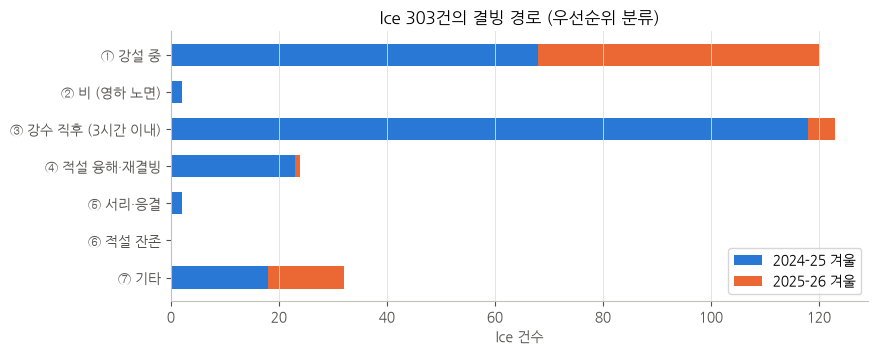

Ice 중 강수 중이거나 강수 후 3시간 이내: 80.9%
Ice 중 직전 24시간 안에 노면이 영상이었던 비율: 97.4%
Ice 중 ASOS 적설이 있는 비율: 72.6%, 적설이 있고 24시간 안에 노면이 영상이었던 비율: 70.6%


,2024-25,2025-26,합계,비율,서해안,통영-대전중부선,호남선
경로,,,,,,,
① 강설 중,68,52,120,0.396,54.0,30.0,36.0
② 비 (영하 노면),2,0,2,0.007,1.0,0.0,1.0
③ 강수 직후 (3시간 이내),118,5,123,0.406,105.0,5.0,13.0
④ 적설 융해·재결빙,23,1,24,0.079,24.0,0.0,0.0
⑤ 서리·응결,2,0,2,0.007,2.0,0.0,0.0
⑥ 적설 잔존,0,0,0,0.000,0.0,0.0,0.0
⑦ 기타,18,14,32,0.106,25.0,5.0,2.0


In [6]:
m["노면최고24h"] = m.groupby("stn")["rst"].transform(lambda s: s.rolling(144, min_periods=1).max())
MECH = ["① 강설 중", "② 비 (영하 노면)", "③ 강수 직후 (3시간 이내)", "④ 적설 융해·재결빙", "⑤ 서리·응결",
        "⑥ 적설 잔존", "⑦ 기타"]
ice_mech = m[m["state"] == 4].copy()
snow_phase = ice_mech["aws_ta"] <= 1.0
ice_mech["경로"] = np.select([
    (ice_mech["aws_rain"] >= 1) & snow_phase,
    (ice_mech["aws_rain"] >= 1) & ~snow_phase,
    ice_mech["강수후경과h"] <= 3,
    (ice_mech["snow"] > 0) & (ice_mech["노면최고24h"] > 0),
    ice_mech["노면-이슬점"] <= 0,
    ice_mech["snow"] > 0,
], MECH[:6], MECH[6])
mech_tbl = pd.crosstab(ice_mech["경로"], ice_mech["winter"]).reindex(MECH, fill_value=0)
mech_tbl["합계"] = mech_tbl.sum(axis=1)
mech_tbl["비율"] = mech_tbl["합계"] / mech_tbl["합계"].sum()
mech_tbl = mech_tbl.join(pd.crosstab(ice_mech["경로"], ice_mech["노선"]).reindex(columns=config.TARGET_ROUTES)).fillna(0)

fig, ax = plt.subplots(figsize=(9, 3.5))
left = np.zeros(len(MECH))
for w, color in zip(["2024-25", "2025-26"], [PALETTE[0], PALETTE[1]]):
    ax.barh(MECH, mech_tbl[w], left=left, color=color, height=0.6, label=f"{w} 겨울")
    left += mech_tbl[w].to_numpy()
ax.invert_yaxis()
ax.set_xlabel("Ice 건수")
ax.set_title("Ice 303건의 결빙 경로 (우선순위 분류)")
ax.legend()
ax.grid(axis="y", visible=False)
plt.show()
print(f"Ice 중 강수 중이거나 강수 후 3시간 이내: {((ice_mech['aws_rain'] >= 1) | (ice_mech['강수후경과h'] <= 3)).mean():.1%}")
print(f"Ice 중 직전 24시간 안에 노면이 영상이었던 비율: {(ice_mech['노면최고24h'] > 0).mean():.1%}")
print(f"Ice 중 ASOS 적설이 있는 비율: {(ice_mech['snow'] > 0).mean():.1%}, "
      f"적설이 있고 24시간 안에 노면이 영상이었던 비율: {((ice_mech['snow'] > 0) & (ice_mech['노면최고24h'] > 0)).mean():.1%}")
mech_tbl.round(3)

- **Ice의 81%는 눈·비가 오는 중이거나 그친 지 3시간 안에 나온다** (① 40%, ③ 41%). 수분 공급이 결빙의 전제라는 H1과 맞다.
- Ice의 97%는 직전 24시간 안에 노면이 영상이었고, 71%는 적설과 함께 나왔다. 융해·재결빙의 조건은 대부분의 Ice에 갖춰져 있지만,
  강수와 겹치지 않는 순수한 융해·재결빙(④)은 8%이다. 와이오밍 제안서의 "녹은 눈의 재결빙이 가장 흔하다"는 이 자료에서는
  강수와 분리되지 않는다 (H4 부분 지지).
- 겨울마다 경로가 다르다. 2024-25는 Ice 231건 중 절반(118건)이 강수 직후(③)이고 대부분 서해안선이다(5-4의 야간 집중과 같은 사례).
  2025-26은 72건 중 52건이 강설 중(①)이다. 내륙 노선(통영-대전중부선·호남선) Ice는 70~75%가 강설 중이다.
- 서리·응결(⑤)과 비(②)는 각 2건뿐이다. Jang(2024)이 다룬 서리 결빙은 이 자료의 Ice에서 거의 나타나지 않는다 (13-3).

### 13-3. 서리 조건 (H3)

Jang(2024)의 서리 조건(노면온도 ≤ 0°C, 노면온도 ≤ 이슬점)을 기온·습도를 직접 재는 9개소에서 계산한다.
이슬점은 같은 관측소의 기온·습도로 Magnus 식(β=17.62, λ=243.12°C)을 써서 구한다.

In [7]:
own = m[m["ta"].notna() & m["rh"].gt(0) & m["rst"].notna()].copy()
gam = np.log(own["rh"] / 100) + 17.62 * own["ta"] / (243.12 + own["ta"])
own["td_own"] = 243.12 * gam / (17.62 - gam)
own["서리조건"] = (own["rst"] <= 0) & (own["rst"] <= own["td_own"])
own["서리조건_AWS"] = (own["rst"] <= 0) & (own["rst"] <= own["aws_td"])
print(f"{own['stn'].nunique()}개소 {len(own):,}건 중 서리 조건 {own['서리조건'].mean():.2%}")
print("관측소별 서리 조건 비율:", own.groupby("stn")["서리조건"].mean().rename(st_info["지점명"]).round(3).to_dict())
print(f"관측소 이슬점 - 최근접 AWS 이슬점: 평균 {(own['td_own'] - own['aws_td']).mean():.2f}°C, "
      f"MAE {(own['td_own'] - own['aws_td']).abs().mean():.2f}°C")
pd.crosstab(own["서리조건"], own["서리조건_AWS"], rownames=["관측소 이슬점 기준"], colnames=["최근접 AWS 이슬점 기준"])

9개소 307,061건 중 서리 조건 1.98%
관측소별 서리 조건 비율: {'군산휴(도)': 0.001, '서김제(도)': 0.001, '부안고려청자휴(도)': 0.006, '고인돌휴(도)': 0.017, '여산휴(도)': 0.027, '삼례졸음(도)': 0.041, '정읍휴(도)': 0.033, '덕유산휴(도)': 0.003, '용포1교(도)': 0.05}
관측소 이슬점 - 최근접 AWS 이슬점: 평균 0.79°C, MAE 1.58°C


최근접 AWS 이슬점 기준,False,True
관측소 이슬점 기준,,
False,300086,898
True,5651,426


In [8]:
frost_tbl = own[own["state"].notna()].groupby("state")["서리조건"].agg(["size", "mean"])
frost_tbl.columns = ["관측수", "서리 조건 비율"]
frost_tbl["서리 조건일 때 이 상태 비율"] = own.loc[own["서리조건"], "state"].value_counts(normalize=True)
frost_tbl.rename(index=STATE_NAMES).round(4)

,관측수,서리 조건 비율,서리 조건일 때 이 상태 비율
state,,,
Dry,220527,0.0120,0.4357
Wet,33711,0.0389,0.2161
Snow,1248,0.0938,0.0193
Ice,183,0.1148,0.0035
저시정,84,0.0000,NaN
Damp+저온(제빙),11785,0.0210,0.0406
결빙시작(제빙),200,0.0500,0.0016
Damp,37124,0.0360,0.2200
판별불가,2138,0.1796,0.0632


Jang(2024)은 서리가 **기온과 습도가 함께 오를 때** 잘 생긴다고 보고, 전날 대비 기온·습도 변화를 입력으로 썼다.
노면이 영하인 시간 중 서리 조건과 그렇지 않은 때의 3시간 변화와, 밤(0~7시) 평균의 전날 밤 대비 변화를 비교한다.

In [9]:
own = own.sort_values(["stn", "time"])
own["기온 3시간 변화"] = own.groupby("stn")["ta"].diff(18)
own["습도 3시간 변화"] = own.groupby("stn")["rh"].diff(18)
cold_own = own[own["rst"] <= 0]
night_own = own[own["hour"] <= 7]
nights = night_own.groupby(["stn", "date"]).agg(ta=("ta", "mean"), rh=("rh", "mean"), rst_min=("rst", "min"),
                                                 frost=("서리조건", "any"))
nights["기온 전날 대비"] = nights.groupby("stn")["ta"].diff()
nights["습도 전날 대비"] = nights.groupby("stn")["rh"].diff()
cold_nights = nights[nights["rst_min"] <= 0].dropna(subset=["기온 전날 대비", "습도 전날 대비"])


def change_summary(df, flag, dta, drh):
    """서리 여부별 기온·습도 변화 요약."""
    g = df.groupby(flag)
    return pd.DataFrame({"관측수": g.size(), "기온 변화 중앙값(°C)": g[dta].median(), "습도 변화 중앙값(%p)": g[drh].median(),
                         "기온·습도 동시 상승 비율": ((df[dta] > 0) & (df[drh] > 0)).groupby(df[flag]).mean()})


pd.concat([
    change_summary(cold_own, "서리조건", "기온 3시간 변화", "습도 3시간 변화").rename(
        index={True: "서리 조건", False: "노면 ≤ 0°C, 서리 조건 아님"}),
    change_summary(cold_nights, "frost", "기온 전날 대비", "습도 전날 대비").rename(
        index={True: "서리 밤", False: "노면 영하, 서리 없는 밤"}),
], keys=["10분 자료: 3시간 변화", "밤(0~7시) 평균: 전날 밤 대비"]).round(3)

관측수  기온 변화 중앙값(°C)  습도 변화 중앙값(%p)  기온·습도 동시 상승 비율
10분 자료: 3시간 변화      노면 ≤ 0°C, 서리 조건 아님  78921         -1.000          3.200           0.089
                    서리 조건                6077          0.700          2.400           0.515
밤(0~7시) 평균: 전날 밤 대비 노면 영하, 서리 없는 밤       1042         -1.171         -0.020           0.200
                    서리 밤                  176          0.559          3.748           0.432

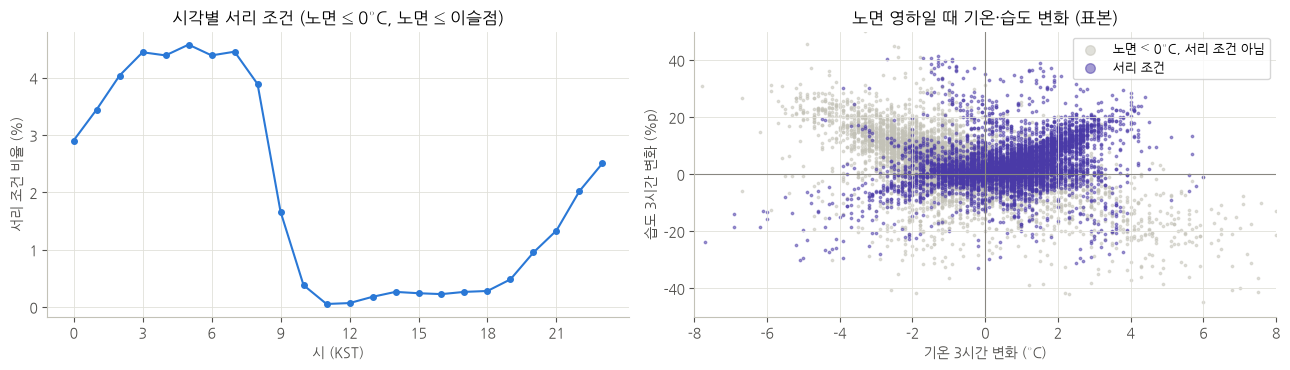

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(range(24), own.groupby("hour")["서리조건"].mean() * 100, marker="o", markersize=4)
axes[0].set_xticks(range(0, 24, 3))
axes[0].set_xlabel("시 (KST)")
axes[0].set_ylabel("서리 조건 비율 (%)")
axes[0].set_title("시각별 서리 조건 (노면 ≤ 0°C, 노면 ≤ 이슬점)")
for frost, color, label in [(False, "#c3c2b7", "노면 ≤ 0°C, 서리 조건 아님"), (True, PALETTE[6], "서리 조건")]:
    d = cold_own[cold_own["서리조건"] == frost].dropna(subset=["기온 3시간 변화", "습도 3시간 변화"])
    d = d.sample(min(len(d), 6000), random_state=0)
    axes[1].scatter(d["기온 3시간 변화"], d["습도 3시간 변화"], s=3, color=color, alpha=0.5, label=label)
axes[1].axhline(0, color=MUTED, linewidth=0.8)
axes[1].axvline(0, color=MUTED, linewidth=0.8)
axes[1].set_xlim(-8, 8)
axes[1].set_ylim(-50, 50)
axes[1].set_xlabel("기온 3시간 변화 (°C)")
axes[1].set_ylabel("습도 3시간 변화 (%p)")
axes[1].set_title("노면 영하일 때 기온·습도 변화 (표본)")
axes[1].legend(markerscale=4, fontsize=9)
plt.tight_layout()
plt.show()

- 서리 조건은 9개소 시간의 2%이고, 새벽 3~7시에 4~5%로 가장 많다. 내륙 평지(삼례졸음·정읍휴)와 용포1교에서 3~5%로 잦고,
  해안의 군산휴·서김제는 0.1%이다.
- **서리 조건은 기온과 습도가 함께 오를 때 생긴다.** 3시간 동안 둘 다 오른 비율이 서리 조건에서 52%, 그 밖의 영하 노면에서 9%이다.
  Jang(2024)처럼 전날 밤과 비교해도 서리 밤은 기온 +0.6°C, 습도 +3.7%p로, 서리 없는 밤(기온 -1.2°C)과 반대이다.
  따뜻하고 습한 공기가 차가운 노면 위로 들어오면 노면이 이슬점보다 낮아진다는 물리적 설명과 맞는다 (H3의 조건 부분 지지).
- 그러나 **서리 조건일 때 센서 노면상태는 Dry 44%, Damp·Wet 44%이고 Ice는 0.35%뿐이다.** Ice 중 서리 조건인 것은 11%이다.
  광학 노면센서는 서리를 Ice로 거의 판정하지 않는다. Jang(2024)이 서리 조건으로 만든 라벨과 이 과제의 Ice는 다른 대상이며,
  그 연구의 정확도 95%를 이 과제와 비교할 수 없다.
- 최근접 AWS 이슬점으로 계산하면 관측소 기준 서리 조건 6,077건 중 426건만 일치한다. 관측소 이슬점이 AWS보다 평균 0.8°C 높다.
  미관측 구간에서 보간 이슬점으로 서리를 판정하면 불확실성이 크다.

### 13-4. 냉각 속도, 동결-융해, 일출·일몰 (H4, H5)

사전 검토에서 핵심 변수 후보로 꼽힌 노면 냉각 속도, 하루 동안 0°C를 넘나든 횟수, 일몰 후 경과시간을 확인한다.

In [11]:
m["노면변화1h"] = m.groupby("stn")["rst"].diff(6)
pd.DataFrame({
    "Ice": m.loc[m["state"] == 4, "노면변화1h"].describe(percentiles=[0.25, 0.5, 0.75]),
    "노면 ≤ 0°C 비결빙": m.loc[m["cold_dry"], "노면변화1h"].describe(percentiles=[0.25, 0.5, 0.75]),
}).T[["count", "25%", "50%", "75%"]].round(2)

,count,25%,50%,75%
Ice,303.0,-1.3,-0.5,0.1
노면 ≤ 0°C 비결빙,168583.0,-0.7,-0.3,0.1


In [12]:
def zero_crossings(s):
    above = (s > 0).astype(float).where(s.notna())
    return int((above.diff().abs() == 1).sum())


day_ft = m.groupby(["stn", "date"]).agg(교차=("rst", zero_crossings), 최저=("rst", "min"), 최고=("rst", "max"),
                                        Ice=("state", lambda s: (s == 4).any()),
                                        결빙관련=("state", lambda s: s.isin([3, 4, 13, 15]).any()))
day_ft["교차 횟수"] = pd.cut(day_ft["교차"], [-1, 0, 1, 2, 4, 100], labels=["0", "1", "2", "3~4", "5 이상"])
day_ft["날 유형"] = np.select([day_ft["최고"] <= 0, day_ft["최저"] <= 0], ["종일 영하", "영하↔영상 교차"], "영하 없음")
pd.concat([
    day_ft.groupby("교차 횟수", observed=True).agg(지점일수=("Ice", "size"), Ice일_비율=("Ice", "mean"),
                                                결빙관련일_비율=("결빙관련", "mean")),
    day_ft.groupby("날 유형").agg(지점일수=("Ice", "size"), Ice일_비율=("Ice", "mean"), 결빙관련일_비율=("결빙관련", "mean")),
], keys=["노면 0°C 교차 횟수", "날 유형"]).round(3)

지점일수  Ice일_비율  결빙관련일_비율
노면 0°C 교차 횟수 0         1526    0.009     0.034
             1          492    0.016     0.069
             2         1036    0.030     0.146
             3~4        552    0.060     0.210
             5 이상       474    0.097     0.287
날 유형         영하 없음     1493    0.005     0.021
             영하↔영상 교차  2554    0.046     0.171
             종일 영하       33    0.182     0.606

- Ice일 때 노면은 1시간에 0.5°C(중앙값) 식고 있어 노면 영하·비결빙(0.3°C)보다 조금 빠르지만, 분포가 많이 겹친다.
- 노면이 하루에 0°C를 여러 번 넘나들수록 Ice가 나온 날이 많아진다 (0회 0.9% → 5회 이상 9.7%, 결빙관련 3.4% → 28.7%).
  노면이 0°C 부근을 오르내리는 날은 흐리고 눈·비가 오는 날이다. 종일 영하인 날(33지점-일, 한파 + 적설)은 Ice 18%, 결빙관련 61%로 가장 높다.

일출·일몰 시각(NOAA 근사식, 전북 중심 35.8°N 127.0°E)을 기준으로 결빙 시각을 본다.
Hong et al.(2022)이 분석한 블랙아이스 사고는 평균 07:05, 일출(07:28) 무렵에 났다.

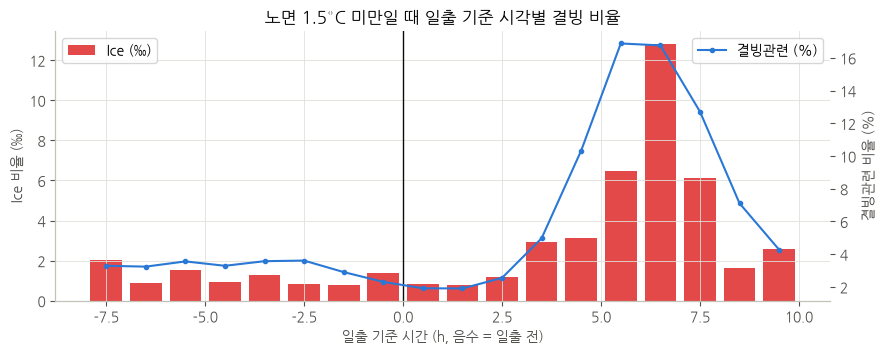

일출 6.89~7.70시, 일몰 17.31~18.42시 (분석 기간)
Ice의 일몰 후 경과시간 사분위(h): {0.25: 5.1, 0.5: 9.3, 0.75: 14.7}


In [13]:
def sun_times(dates, lat=35.8, lon=127.0):
    """일출·일몰 시각 (KST, 시 단위 소수). NOAA 근사식."""
    n = pd.DatetimeIndex(dates).dayofyear.to_numpy()
    g_ = 2 * np.pi / 365 * (n - 1)
    eqt = 229.18 * (0.000075 + 0.001868 * np.cos(g_) - 0.032077 * np.sin(g_) - 0.014615 * np.cos(2 * g_)
                    - 0.040849 * np.sin(2 * g_))
    decl = (0.006918 - 0.399912 * np.cos(g_) + 0.070257 * np.sin(g_) - 0.006758 * np.cos(2 * g_)
            + 0.000907 * np.sin(2 * g_) - 0.002697 * np.cos(3 * g_) + 0.00148 * np.sin(3 * g_))
    phi = np.radians(lat)
    ha = np.degrees(np.arccos(np.cos(np.radians(90.833)) / (np.cos(phi) * np.cos(decl)) - np.tan(phi) * np.tan(decl)))
    noon = 720 - 4 * lon - eqt + 540  # 남중 시각 (분, KST)
    return (noon - 4 * ha) / 60, (noon + 4 * ha) / 60


rise, sset = sun_times(m["date"])
clock = (m["time"].dt.hour + m["time"].dt.minute / 60).to_numpy()
m["일몰후h"] = np.where(clock >= sset, clock - sset, clock + 24 - sset)
m["일출기준h"] = clock - rise
ref = m[(m["rst"] < 1.5) & m["state"].notna()]
by_sun = ref.groupby(pd.cut(ref["일출기준h"], np.arange(-14, 11, 1)), observed=True)["state"].agg(
    관측수="size", Ice=lambda s: (s == 4).mean() * 1000, 결빙관련=lambda s: s.isin([3, 4, 13, 15]).mean() * 100)
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar([c.mid for c in by_sun.index], by_sun["Ice"], width=0.8, color=PALETTE[7], label="Ice (‰)")
ax2 = ax.twinx()
ax2.plot([c.mid for c in by_sun.index], by_sun["결빙관련"], color=PALETTE[0], marker="o", markersize=3, label="결빙관련 (%)")
ax2.grid(False)
ax.axvline(0, color=INK, linewidth=1)
ax.set_xlabel("일출 기준 시간 (h, 음수 = 일출 전)")
ax.set_ylabel("Ice 비율 (‰)")
ax2.set_ylabel("결빙관련 비율 (%)")
ax.set_title("노면 1.5°C 미만일 때 일출 기준 시각별 결빙 비율")
ax.legend(loc="upper left")
ax2.legend(loc="upper right")
plt.show()
print(f"일출 {rise.min():.2f}~{rise.max():.2f}시, 일몰 {sset.min():.2f}~{sset.max():.2f}시 (분석 기간)")
print("Ice의 일몰 후 경과시간 사분위(h):", m.loc[m["state"] == 4, "일몰후h"].quantile([0.25, 0.5, 0.75]).round(1).to_dict())

- 노면이 1.5°C 미만일 때 Ice 비율은 **일출 무렵에 가장 낮고(약 1‰), 일출 5~8시간 뒤 한낮에 가장 높다(6~13‰).**
  한낮에도 노면이 차가운 날은 눈·비가 오는 흐린 날이고, 새벽의 차가운 노면은 대부분 맑고 건조한 밤의 복사냉각이기 때문이다.
- 사고가 일출 무렵에 많은 것(Hong et al. 2022)은 어둡고 교통량이 늘어나는 시간이라는 영향도 크다. 이 자료에서 "일출 무렵" 자체가
  결빙을 늘리지는 않으므로, 시각 변수만으로 위험을 높게 잡으면 안 된다. 시각보다 수분 조건이 먼저다.
- Ice는 일몰 후 5~15시간(중앙값 약 9시간, 새벽 3시 무렵)에 많지만, 이는 노면이 영하인 시간 자체가 밤에 많기 때문이다.